In [1]:
import pandas as pd
import json
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("Biblioteker lastet inn!")

W1120 15:06:23.731000 27289 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Matplotlib is building the font cache; this may take a moment.


Biblioteker lastet inn!


In [2]:
with open("../data/diagnoses_clean.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} diagnoser")
df.head()

Lastet 5 diagnoser


,id,diagnosis,diagnosis_clean
0,J0001,Hysteria med kramper,hysteria med kramper
1,J0002,"ex constitutione, svak konstitusjon","ex constitutione, svak konstitusjon"
2,J0003,Hysterisk personlighet,hysterisk personlighet
3,J0005,Epilepsi med hysteriske trekk,epilepsi med hysteriske trekk
4,J0007,ukjent,ukjent


In [3]:
# Last inn en flerspråklig modell som forstår norsk
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Lag embeddings
embeddings = model.encode(df["diagnosis_clean"].tolist())

print(f"Embeddings laget: {embeddings.shape}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings laget: (5, 384)


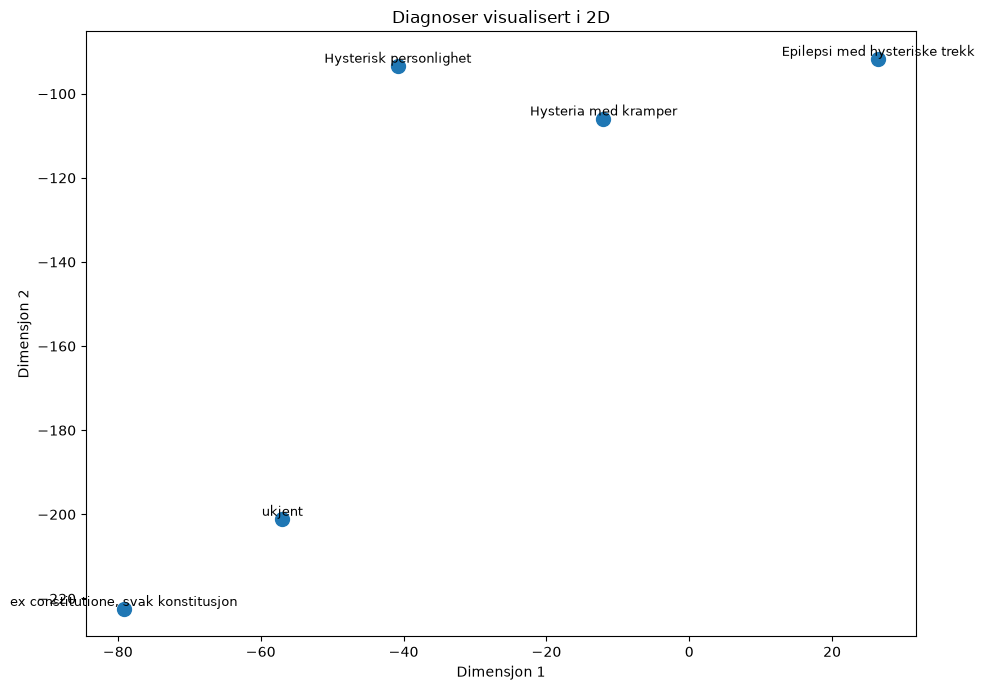

Plot lagret!


In [4]:
# Reduser fra 384 dimensjoner til 2 (for å kunne plotte)
# Med så lite data bruker vi perplexity=2
tsne = TSNE(n_components=2, random_state=42, perplexity=2)
coords = tsne.fit_transform(embeddings)

# Plot
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(coords[:, 0], coords[:, 1], s=100)

# Legg til diagnosetekst ved siden av hver prikk
for i, row in df.iterrows():
    ax.annotate(row["diagnosis"], (coords[i, 0], coords[i, 1]),
                fontsize=9, ha="center", va="bottom")

ax.set_title("Diagnoser visualisert i 2D")
ax.set_xlabel("Dimensjon 1")
ax.set_ylabel("Dimensjon 2")
plt.tight_layout()
plt.savefig("../results/diagnose_kart.png", dpi=150)
plt.show()

print("Plot lagret!")

In [5]:
# Lagre embeddings som numpy-fil
np.save("../data/embeddings.npy", embeddings)
print("Embeddings lagret!")

Embeddings lagret!
